# Stage 6: efficiency benchmark

Results of `python -m src.benchmark`. Everything is measured on the same machine (specs below).

- **train time**: final fit on train + validation;
- **model-only latency**: one sample, and per sample in a batch of 1,000 (median, after warm-up);
- **end-to-end latency**: building the features for one forecast + the model;
- **size**: the model file on disk;
- **exports**: ONNX (float32) for the GBMs and the LSTM, int8 dynamic quantization for the LSTM,
  each scored again on the test set.

In [1]:
import pandas as pd
from IPython.display import Image

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLES = "../results/tables/"
FIGURES = "../results/figures/"

In [2]:
eff = pd.read_csv(TABLES + "06_efficiency.csv")
eff[["cpu", "cores", "ram_gb", "os", "python"]].drop_duplicates()

,cpu,cores,ram_gb,os,python
0,Intel(R) Core(TM) i5-3437U CPU @ 1.90GHz,4,5.7,Linux-6.18.58.1-microsoft-standard-WSL2-x86_64...,3.14.4


## 1. Cost and accuracy of every model

In [3]:
columns = ["horizon", "model", "train_seconds", "single_ms", "batch_ms_per_sample", "end_to_end_single_ms", "size_kB", "test_nmae_pct"]
eff[columns].round(4)

,horizon,model,train_seconds,single_ms,batch_ms_per_sample,end_to_end_single_ms,size_kB,test_nmae_pct
0,15min,last_value,0.0000,0.0010,0.0000,58.4656,0.0000,5.3233
1,15min,ridge,7.6664,1.0319,0.0026,59.4965,3.1728,4.9748
2,15min,lgbm,36.8000,0.1461,0.0072,58.6107,2014.2656,4.6456
3,15min,lgbm_onnx,NaN,0.0495,0.0037,58.5141,1602.3740,4.6454
4,15min,xgb,60.7000,0.8128,0.0091,59.2774,9286.3984,4.6085
5,15min,xgb_onnx,NaN,0.0895,0.0137,58.5541,5420.2568,4.6085
6,15min,lstm,421.4000,0.6300,0.0436,59.0946,103.2432,4.8571
7,15min,lstm_onnx,NaN,0.1996,0.0325,58.6642,100.3379,4.8571
8,15min,lstm_int8,NaN,2.8146,0.1065,61.2792,32.6924,4.9163
9,1h,last_value,0.0000,0.0004,0.0000,50.1272,0.0000,9.0047


## 2. Feature construction dominates one forecast
`feature_ms` is the same for every model of a horizon.

In [4]:
eff.groupby("horizon")["feature_ms"].first().round(1)

horizon
15min       58.5
1h          50.1
dayahead    63.3
Name: feature_ms, dtype: float64

## 3. Exports: does accuracy change?
A change of 0 means the exported model gives the same error as the original.

In [5]:
exports = eff[eff["model"].str.contains("onnx|int8")]
exports[["horizon", "model", "size_kB", "single_ms", "test_nmae_pct", "nmae_change_vs_original_pct_points", "note"]].round(4)

,horizon,model,size_kB,single_ms,test_nmae_pct,nmae_change_vs_original_pct_points,note
3,15min,lgbm_onnx,1602.3740,0.0495,4.6454,-0.0002,ONNX float32
5,15min,xgb_onnx,5420.2568,0.0895,4.6085,-0.0000,ONNX float32
7,15min,lstm_onnx,100.3379,0.1996,4.8571,-0.0000,ONNX float32
8,15min,lstm_int8,32.6924,2.8146,4.9163,0.0592,"torch dynamic quantization, int8 (qnnpack); cr..."
12,1h,lgbm_onnx,3096.2383,0.0865,4.9526,-0.0007,ONNX float32
14,1h,xgb_onnx,2537.7891,0.0872,4.9487,-0.0000,ONNX float32
16,1h,lstm_onnx,97.3379,0.2632,5.2414,-0.0000,ONNX float32
17,1h,lstm_int8,31.8955,4.1596,5.2624,0.0210,"torch dynamic quantization, int8 (qnnpack)"
21,dayahead,lgbm_onnx,33.7432,0.0399,9.7793,-0.0000,ONNX float32
23,dayahead,xgb_onnx,61.7432,0.0418,9.7496,0.0000,ONNX float32


## 4. Accuracy vs latency

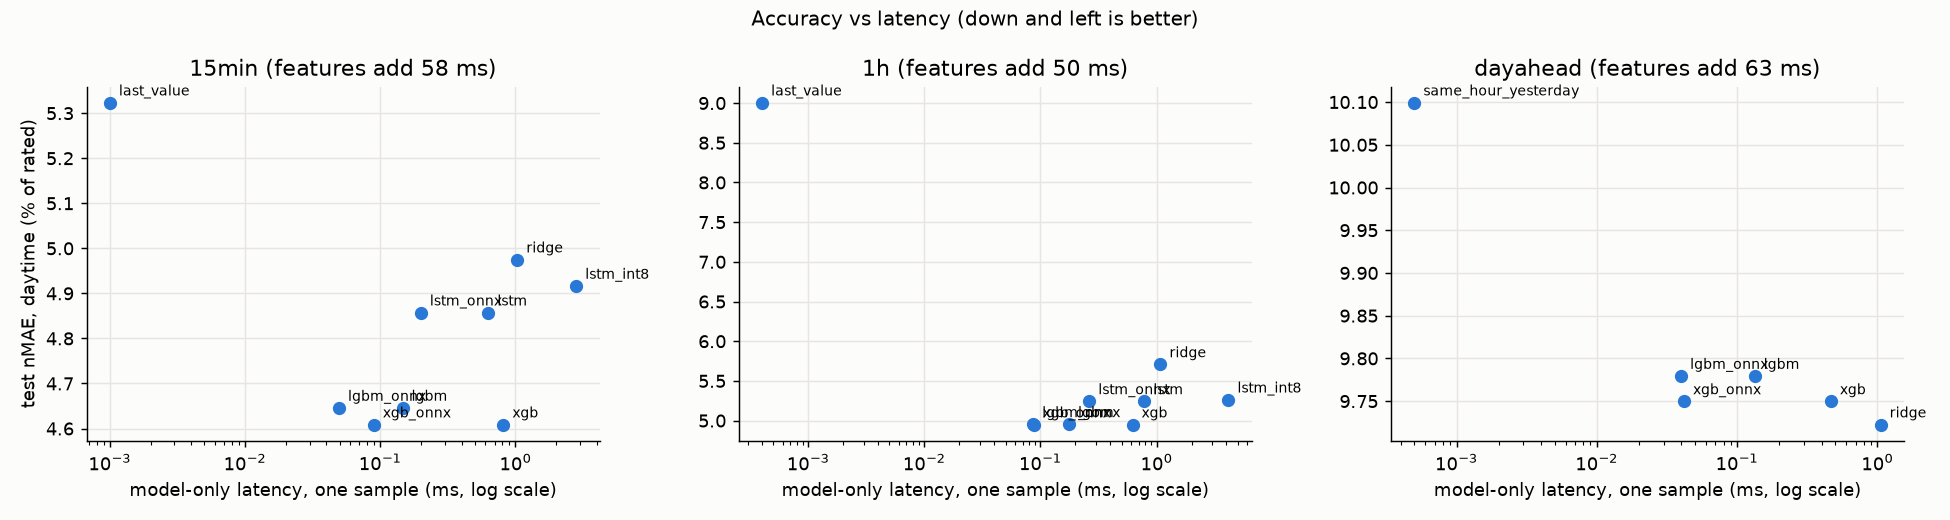

In [6]:
Image(FIGURES + "06_accuracy_vs_latency.png")